# UpShift: final job-matching model
**Team:** Hafswa, Collins and Shifla · **Final approach:** MiniLM job matching, with logistic regression for feedback tone.

We want to help a student find suitable early-career jobs and see what to work on next. This notebook follows the complete process: data → cleaning → exploration → model comparison → evaluation → app examples → saving and reloading.

**How to run:** use a fresh Colab runtime and run all; Step 1 loads the original data from our shared Drive after sign-in. Local Jupyter users choose their own data folder. The first run needs internet for packages, the pretrained model and TweetEval. It does not need another project notebook or Python file. Long shared functions are in expandable setup cells; the numbered steps are the presentation walkthrough. We do not upload real student CVs here.

## 1. Set up — works without our personal folders
**Recommended for the lecturer: Google Colab.**
1. Open this notebook in Colab and choose **Runtime → Run all**.
2. Complete the Google sign-in prompt in this step. Use the account that has **Viewer access** to our [shared project folder](https://drive.google.com/drive/folders/11kEwky5_pJ6IpLfNWepHzNfzI0vKkW-2).
3. The next cell loads the three original CSVs directly from Drive. No folder-path editing or Drive shortcuts are needed. Allow the run to finish; the first CPU run can take around 30 minutes.

**On a local PC/Mac/Linux computer:** open the notebook in a dedicated Python 3.12/Jupyter environment. Download and extract `Resume.csv`, `postings.csv` and `skills_en.csv` from [AI Datasets](https://drive.google.com/drive/folders/1OS_u2gUFYCGqZtl-Q2izLvgZZSFi9ZS9). When prompted below, paste the path to **your own** dataset folder. Nested folders are supported; no particular username or Downloads location is required. Use the recorded package versions if your existing environment differs.

The loader checks that these are the same original files used in the saved results. It never changes the shared Drive files. Outputs are written to `UpShift_Final_Output`; in Colab, download `UpShift_Final_Model.zip` from the Files panel before ending the runtime if you want to keep the generated model.

Colab installs the recorded package versions and removes optional image/audio packages that caused the earlier import error. If it asks for a restart after installation, restart once and run all again. **Access denied?** Ask the team to give the Google account you signed in with Viewer access, then rerun this step. Shared data cannot be downloaded without permission.

In [1]:
import os, sys, subprocess, importlib.util
from pathlib import Path

try:
    from google.colab import auth
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Use Colab, or a dedicated local Python/Jupyter environment.
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y',
                    'torchvision', 'torchaudio'], check=True, capture_output=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu'], check=True)
packages = ['numpy==2.2.6', 'pandas==2.3.3', 'scipy==1.16.3',
            'scikit-learn==1.7.2', 'joblib==1.5.2', 'nltk==3.9.2',
            'sentence-transformers==5.1.2', 'transformers==4.57.1', 'matplotlib==3.10.7']
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    *packages, 'google-api-python-client'], check=True)
else:
    modules = ['numpy','pandas','scipy','sklearn','joblib','nltk','sentence_transformers','transformers','matplotlib','torch']
    if any(importlib.util.find_spec(name) is None for name in modules):
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                        'torch==2.9.0', *packages], check=True)

os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'
os.environ['HF_HUB_DISABLE_XET'] = '1'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
START_FOLDER = Path.cwd().resolve()
if START_FOLDER.name == 'UpShift_Final_Output': START_FOLDER = START_FOLDER.parent
print('Ready. Next: shared Drive sign-in in Colab, or your own data-folder path locally.')

Ready. Next: shared Drive sign-in in Colab, or your own data-folder path locally.


In [2]:
import hashlib

SHARED_FOLDER = 'https://drive.google.com/drive/folders/11kEwky5_pJ6IpLfNWepHzNfzI0vKkW-2'
DATA_FILES = {'Resume.csv': {'id': '1FzjIBEPOJz3bGIiqditVTZaqWl8FcNUM', 'sha256': '816a7cd985a9a41e3ce8d1e83cb7e1beb1e854a89c1cf1fd0d75494faaa0559d'}, 'postings.csv': {'id': '1WFICdaoMZvyQdL2sy_rieKr88vVgFSM-', 'sha256': 'de33f27c8d1b226014e0cede003404e9b0acb66db718671fda9b3e3538eca6ea'}, 'skills_en.csv': {'id': '1_zxUO2PbLr3N4cJ7kYno6S8Cx_z_NQri', 'sha256': 'd03b10efca94b4bcfa260a992cfde89c375f0fa12095d6662a663cfd2f9f2950'}}

def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b''): digest.update(chunk)
    return digest.hexdigest()

def local_dataset_files(folder, files=DATA_FILES):
    folder = Path(folder).expanduser().resolve()
    if not folder.is_dir(): raise FileNotFoundError('Choose an existing dataset folder.')
    paths = {}
    for name, info in files.items():
        direct = folder / name
        matches = [direct] if direct.is_file() else list(folder.rglob(name))
        if len(matches) != 1:
            raise FileNotFoundError(f'Keep one extracted {name} in the selected folder. Download the original CSVs from the shared Drive.')
        if file_hash(matches[0]) != info['sha256']:
            raise ValueError(f'{name} differs from the original data used for these results. Download the original file from the shared Drive.')
        paths[name] = matches[0]
    return paths

def shared_dataset_files(service, folder, files=DATA_FILES, downloader_class=None):
    if downloader_class is None:
        from googleapiclient.http import MediaIoBaseDownload
        downloader_class = MediaIoBaseDownload
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    for name, info in files.items():
        target = folder / name
        if target.is_file() and file_hash(target) == info['sha256']: continue
        partial = folder / (name + '.part')
        try:
            print('Loading', name, 'from the shared Drive…')
            request = service.files().get_media(fileId=info['id'], supportsAllDrives=True)
            with partial.open('wb') as stream:
                download = downloader_class(stream, request, chunksize=8*1024*1024)
                done = False
                while not done: _, done = download.next_chunk(num_retries=3)
            if file_hash(partial) != info['sha256']:
                raise ValueError(f'{name} did not match the original dataset. Please try again or ask the team to check the file.')
            partial.replace(target)
        except Exception as error:
            partial.unlink(missing_ok=True)
            if isinstance(error, ValueError): raise
            raise RuntimeError('Could not load the shared data. Sign in with a Google account that has Viewer access to the shared folder, check your connection, then rerun this cell.') from error
    return local_dataset_files(folder, files)

if IN_COLAB:
    # Read files by their Drive IDs; no personal My Drive folder paths are used.
    from googleapiclient.discovery import build
    import google.auth
    auth.authenticate_user()
    credentials, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
    drive_service = build('drive', 'v3', credentials=credentials, cache_discovery=False)
    DATA_FOLDER = Path('/content/upshift_data')
    paths = shared_dataset_files(drive_service, DATA_FOLDER)
    WORK = Path('/content/UpShift_Final_Output')
else:
    selected = os.environ.get('UPSHIFT_DATA_DIR') or input('Paste the path to your extracted dataset folder: ')
    DATA_FOLDER = Path(selected.strip().strip('"').strip("'")).expanduser().resolve()
    paths = local_dataset_files(DATA_FOLDER)
    WORK = START_FOLDER / 'UpShift_Final_Output'

resume_path, jobs_path, skills_path = [paths[name] for name in ['Resume.csv','postings.csv','skills_en.csv']]
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
sys.path.insert(0, str(WORK))
for folder in ['upshift_ai', 'data', 'results', 'artifacts']: Path(folder).mkdir(exist_ok=True)
print('Verified: Resume.csv, postings.csv and skills_en.csv. Original files are unchanged.')
print('Results will be saved in UpShift_Final_Output.')

Verified: Resume.csv, postings.csv and skills_en.csv. Original files are unchanged.
Results will be saved in UpShift_Final_Output.


### Shared app functions — expandable setup
These cells contain the same cleaning, skill lookup, matching and prediction functions used by the app. They write a small Python package **from code included here**, so saving/loading the model works without a separate download of project code. Expand them for code review; continue to Step 2 for the main explanation.

In [3]:
%%writefile upshift_ai/__init__.py
"""UpShift NLP: job retrieval, skill evidence and a separate sentiment benchmark."""

__version__ = "1.0.0"

Writing upshift_ai/__init__.py


In [4]:
%%writefile upshift_ai/preprocessing.py
"""Shared preprocessing for training and serving."""

import html
import re
import unicodedata

TOKEN_PATTERN = r"(?u)(?:\.net\b|\b\w+(?:[.+#-]\w+)*(?:\+\+|#)?)"
SECTION_WORDS = {
    "summary",
    "skills",
    "experience",
    "education",
    "objective",
    "profile",
    "highlights",
    "qualifications",
    "career",
    "professional",
}


def plain_text(value):
    if not isinstance(value, str):
        return ""
    value = html.unescape(unicodedata.normalize("NFKC", value))
    value = re.sub(r"<[^>]+>", " ", value)
    return value.replace("\r\n", "\n").replace("\r", "\n").strip()


def clean_text(value):
    value = plain_text(value).lower()
    value = re.sub(r"https?://\S+|www\.\S+|\S+@\S+", " ", value)
    return re.sub(r"\s+", " ", re.sub(r"[^\w+#.\s-]", " ", value)).strip()


def prepare_resume(value):
    value = plain_text(value)
    for _ in range(2):
        pieces = re.split(r"\s{2,}|\n", value, maxsplit=1)
        chunk = pieces[0]
        letters = [c for c in chunk if c.isalpha()]
        first = (re.findall(r"[a-z]+", chunk.lower()) or [""])[0]
        if (
            len(pieces) == 2
            and 0 < len(chunk) <= 80
            and letters
            and sum(c.isupper() for c in letters) / len(letters) > 0.8
            and first not in SECTION_WORDS
        ):
            value = pieces[1].lstrip()
        else:
            break
    value = re.sub(r"\bcompany name\b|\bcity\s*,?\s*state\b", " ", value, flags=re.I)
    return clean_text(value)


def segments(value):
    value = plain_text(value)
    return [
        part.strip(" -\t")
        for part in re.split(
            r"\n+|[;•]|(?<=[.!?])\s+(?=[A-Z0-9])|\bbut\b|\bhowever\b", value, flags=re.I
        )
        if part.strip()
    ]

Writing upshift_ai/preprocessing.py


In [5]:
%%writefile upshift_ai/skills.py
"""Conservative ESCO extraction with stable concept IDs and contextual evidence."""

from dataclasses import dataclass
from collections import defaultdict
import re
from .preprocessing import clean_text, plain_text, segments, TOKEN_PATTERN

MANUAL = {
    "Python": (
        [
            "python",
            "python programming",
            "python language",
            "python (computer programming)",
        ],
        ["Python (computer programming)"],
    ),
    "Java": (
        ["java", "java programming", "java (computer programming)"],
        ["Java (computer programming)"],
    ),
    "JavaScript": (["javascript", "js"], ["JavaScript"]),
    "TypeScript": (["typescript"], ["TypeScript"]),
    "SQL": (["sql", "structured query language"], ["SQL"]),
    "HTML": (["html", "html5"], ["HTML"]),
    "CSS": (["css", "css3"], ["CSS"]),
    "C++": (["c++"], ["C++"]),
    "C#": (["c#", "c sharp"], ["C#"]),
    ".NET": ([".net", "dotnet", "dot net"], [".NET"]),
    "Node.js": (["node.js", "nodejs", "node js"], ["Node.js"]),
    "React": (["react", "react.js", "reactjs"], []),
    "React Native": (["react native"], []),
    "Kotlin": (["kotlin"], ["Kotlin"]),
    "Android": (["android", "android sdk"], []),
    "Firebase": (["firebase"], []),
    "Git": (["git", "git version control"], ["Git"]),
    "Docker": (["docker", "docker containers"], []),
    "Excel": (["excel", "ms excel", "microsoft excel"], ["Microsoft Excel"]),
    "Figma": (["figma"], []),
    "Canva": (["canva"], []),
    "Teamwork": (["teamwork", "team work"], []),
    "Communication": (
        ["communication skills", "written communication", "verbal communication"],
        [],
    ),
    "MySQL": (["mysql"], ["MySQL"]),
    "PostgreSQL": (["postgresql", "postgres"], ["PostgreSQL"]),
    "Linux": (["linux"], ["Linux"]),
    "REST APIs": (["rest api", "rest apis", "restful api", "restful apis"], []),
    "Testing": (["unit testing", "software testing", "automated testing"], []),
    "Research": (["user research", "usability research"], []),
    "Accessibility": (["web accessibility", "digital accessibility", "wcag"], []),
}
AMBIGUOUS = {
    "plan",
    "stand",
    "commitment",
    "less",
    "react",
    "integrity",
    "reliability",
    "history",
    "pregnancy",
    "morality",
    "banking",
    "call",
    "support",
    "english",
    "assume responsibility",
    "approach challenges positively",
}
TECH_SINGLE = {
    clean_text(a)
    for name, (aliases, _) in MANUAL.items()
    for a in aliases
    if " " not in a
}


@dataclass
class SkillLexicon:
    aliases: dict
    concepts: dict
    audit: dict

    def __post_init__(self):
        self.trie = {}
        for alias, sid in self.aliases.items():
            tokens = re.findall(TOKEN_PATTERN, alias)
            if not tokens:
                continue
            node = self.trie
            for token in tokens:
                node = node.setdefault(token, {})
            node["_id"] = sid

    def find(self, text):
        cleaned = clean_text(text)
        tokens = re.findall(TOKEN_PATTERN, cleaned)
        hits = []
        i = 0
        while i < len(tokens):
            node = self.trie
            j = i
            best = None
            while j < len(tokens) and tokens[j] in node:
                node = node[tokens[j]]
                j += 1
                if "_id" in node:
                    best = (j, node["_id"])
            if best:
                end, sid = best
                alias = " ".join(tokens[i:end])
                before = " ".join(tokens[max(0, i - 6) : i])
                after = " ".join(tokens[end : end + 5])
                neg = bool(
                    re.search(r"\b(?:no|not|without|lack|lacking|never)\b", before)
                    or re.search(
                        r"^(?:is |are )?(?:not required|not necessary|not needed|isn t required)",
                        after,
                    )
                )
                if "not only" in before:
                    neg = False
                if alias == "react" and not (
                    re.search(
                        r"\b(?:javascript|frontend|front-end|framework|jsx|web|skills)\b",
                        cleaned,
                    )
                    or re.search(r"\bReact\b", text)
                ):
                    i = end
                    continue
                hits.append(
                    {
                        "id": sid,
                        "label": self.concepts[sid]["label"],
                        "alias": alias,
                        "negated": neg,
                        "evidence": text[:400],
                    }
                )
                i = end
            else:
                i += 1
        return hits

    def profile_skills(self, text):
        return {
            h["id"]
            for part in segments(text)
            for h in self.find(part)
            if not h["negated"]
        }

    def job_skills(self, text):
        found = {
            "required": set(),
            "preferred": set(),
            "mentioned": set(),
            "excluded": set(),
        }
        evidence = []
        mode = "mentioned"
        for part in segments(text):
            lower = part.lower()
            if re.search(
                r"^(?:responsibilities|what you.ll do|about us|about the company|benefits|we offer|our team)\b",
                lower,
            ):
                mode = "mentioned"
            if re.search(
                r"^(?:requirements|qualifications|essential|what you bring|what you.ll need|skills required|technical skills|minimum qualifications)\b",
                lower,
            ):
                mode = "required"
            if re.search(r"^(?:preferred|nice to have|desirable|bonus)\b", lower):
                mode = "preferred"
            current = mode
            if re.search(
                r"\b(?:preferred|nice to have|optional|a plus|desirable|bonus)\b", lower
            ):
                current = "preferred"
            elif re.search(
                r"\b(?:must|required|essential|proficien\w*|knowledge of|experience (?:with|in)|ability to|familiarity with)\b",
                lower,
            ):
                current = "required"
            sentence_negated = (
                bool(re.search(r"not required|not necessary|not needed", lower))
                and not re.search(r"\b(?:is|are) required\b", lower)
                and current != "preferred"
            )
            for hit in self.find(part):
                sid = hit["id"]
                if hit["negated"] or sentence_negated:
                    # "preferred but not required" is handled as a preference, never a requirement.
                    if (
                        current == "preferred"
                        and re.search(r"not required|not necessary", lower)
                        and not re.search(
                            r"\bno (?:experience|knowledge)|\bwithout\b", lower
                        )
                    ):
                        found["preferred"].add(sid)
                    else:
                        found["excluded"].add(sid)
                else:
                    found[current].add(sid)
                evidence.append({**hit, "kind": current})
        found["preferred"] -= found["required"]
        found["mentioned"] -= found["required"] | found["preferred"]
        return {**{k: sorted(v) for k, v in found.items()}, "evidence": evidence}


def build_lexicon(frame):
    frame = frame.fillna("").drop_duplicates("conceptUri")
    concepts = {}
    candidates = defaultdict(set)
    preferred = {}
    for row in frame.to_dict("records"):
        sid = row["conceptUri"]
        label = row["preferredLabel"].strip()
        if not sid or not label:
            continue
        concepts[sid] = {
            "label": label,
            "source": "ESCO",
            "type": row.get("skillType", ""),
        }
        preferred[clean_text(label)] = sid
        for alias in (
            [label]
            + str(row.get("altLabels", "")).split("\n")
            + str(row.get("hiddenLabels", "")).split("\n")
        ):
            alias = clean_text(alias)
            if (
                not alias
                or alias in AMBIGUOUS
                or (len(alias) < 3 and alias not in {"c#", "c++"})
            ):
                continue
            if " " not in alias and alias not in TECH_SINGLE:
                continue
            candidates[alias].add(sid)
    clashes = {a: sorted(ids) for a, ids in candidates.items() if len(ids) > 1}
    aliases = {a: next(iter(ids)) for a, ids in candidates.items() if len(ids) == 1}
    for name, (spellings, targets) in MANUAL.items():
        sid = next(
            (preferred[clean_text(t)] for t in targets if clean_text(t) in preferred),
            None,
        )
        if sid is None:
            sid = "urn:upshift:skill:" + re.sub(r"[^a-z0-9]+", "-", name.lower()).strip(
                "-"
            )
        concepts[sid] = {
            "label": name,
            "source": "ESCO" if sid.startswith("http") else "UpShift extension",
            "type": "knowledge",
        }
        # Keep all existing synonyms for the selected concept, and assign new synonyms to that same ID.
        for alias in spellings:
            aliases[clean_text(alias)] = sid
    return SkillLexicon(
        aliases,
        concepts,
        {
            "ambiguous_aliases_excluded": clashes,
            "alias_count": len(aliases),
            "concept_count": len(concepts),
        },
    )

Writing upshift_ai/skills.py


In [6]:
%%writefile upshift_ai/semantic.py
"""Chunked local embeddings; no document text is sent to hosted inference."""

import hashlib, json
from pathlib import Path
import numpy as np

MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
MODEL_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"


def text_chunks(text, words=160, stride=120, max_chunks=4):
    tokens = str(text).split()
    if not tokens:
        return [""]
    starts = list(range(0, len(tokens), stride))
    if len(starts) > max_chunks:
        starts = [
            starts[i] for i in np.linspace(0, len(starts) - 1, max_chunks, dtype=int)
        ]
    return [" ".join(tokens[i : i + words]) for i in starts]


def load_encoder(path=None):
    import torch
    from sentence_transformers import SentenceTransformer

    torch.set_num_threads(2)
    if path is not None:
        path = Path(path).resolve(strict=True)
        model = SentenceTransformer(str(path), device="cpu", local_files_only=True)
    else:
        model = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, device="cpu")
    model.max_seq_length = 256
    return model


def encode_documents(model, texts, cache_path=None):
    digest = hashlib.sha256(
        json.dumps(list(texts), ensure_ascii=False).encode()
    ).hexdigest()
    settings = {
        "model": MODEL_ID,
        "revision": MODEL_REVISION,
        "max_chunks": 4,
        "words_per_chunk": 160,
        "stride": 120,
        "max_seq_length": 256,
    }
    if cache_path:
        cache_path = Path(cache_path)
        meta = cache_path.with_suffix(".json")
        if cache_path.exists() and meta.exists():
            saved = json.loads(meta.read_text())
            if saved.get("sha256") == digest and all(
                saved.get(k) == v for k, v in settings.items()
            ):
                return np.load(cache_path)
    groups = [text_chunks(t) for t in texts]
    flat = [c for group in groups for c in group]
    print(f"Embedding {len(texts)} documents in {len(flat)} sampled chunks", flush=True)
    embeddings = model.encode(
        flat,
        batch_size=32,
        normalize_embeddings=True,
        show_progress_bar=True,
        convert_to_numpy=True,
    )
    rows = []
    pos = 0
    for group in groups:
        vector = embeddings[pos : pos + len(group)].mean(axis=0)
        pos += len(group)
        rows.append(vector / max(np.linalg.norm(vector), 1e-12))
    vectors = np.asarray(rows, dtype=np.float32)
    if cache_path:
        np.save(cache_path, vectors)
        meta.write_text(json.dumps({"sha256": digest, **settings}))
    return vectors

Writing upshift_ai/semantic.py


In [7]:
%%writefile upshift_ai/matching.py
"""Shared recommendation contract for the notebook and Python service."""

import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from .preprocessing import prepare_resume


def recommend(
    bundle,
    resume_text,
    top_k=5,
    method="lexical",
    min_similarity=0.0,
    encoder=None,
    live_only=False,
):
    if not isinstance(resume_text, str) or not resume_text.strip():
        raise ValueError("Provide non-empty profile or CV text.")
    if len(resume_text) > 50000:
        raise ValueError("CV text exceeds 50,000 characters.")
    if isinstance(top_k, bool) or not isinstance(top_k, int) or not 1 <= top_k <= 20:
        raise ValueError("top_k must be an integer between 1 and 20.")
    if method not in {"lexical", "semantic"}:
        raise ValueError("method must be lexical or semantic.")
    if not isinstance(min_similarity, (float, int)) or not 0 <= min_similarity <= 1:
        raise ValueError("min_similarity must be in [0,1].")
    vector = bundle["retriever"].transform([prepare_resume(resume_text)])
    if vector.nnz == 0:
        return {
            "status": "no_match",
            "method": method,
            "matches": [],
            "catalogue_status": "historical_research_not_live",
        }
    if method == "semantic":
        if encoder is None:
            raise ValueError("Semantic encoder must be loaded for semantic requests.")
        from .semantic import encode_documents

        scores = (
            encode_documents(encoder, [prepare_resume(resume_text)])
            @ bundle["semantic_vectors"].T
        ).ravel()
    else:
        scores = cosine_similarity(vector, bundle["job_vectors"]).ravel()
    profile_skills = bundle["lexicon"].profile_skills(resume_text)
    order = np.argsort(-scores, kind="stable")
    matches = []
    for pos in order:
        if len(matches) >= top_k:
            break
        score = float(scores[pos])
        if score <= min_similarity:
            continue
        row = bundle["jobs"].iloc[int(pos)]
        if live_only and (
            bool(row["is_expired"]) or row["eligibility_status"] != "verified"
        ):
            continue
        skillsets = bundle["job_skills"][int(pos)]
        required = set(skillsets["required"])
        preferred = set(skillsets["preferred"])

        def present(ids):
            return [
                {"id": sid, "label": bundle["lexicon"].concepts[sid]["label"]}
                for sid in sorted(
                    ids, key=lambda x: bundle["lexicon"].concepts[x]["label"]
                )
            ]

        matched = required & profile_skills
        unmentioned = required - profile_skills
        coverage = len(matched) / len(required) if required else None
        matches.append(
            {
                "job_id": str(row.job_id),
                "title": str(row.title),
                "company_name": str(row.company_name),
                "description": str(row.description),
                "location": str(row.location),
                "work_type": str(row.formatted_work_type),
                "experience_level": str(row.formatted_experience_level),
                "similarity": round(score, 6),
                "ranking_method": method,
                "skill_coverage": coverage,
                "skills_match_percentage": round(coverage * 100)
                if coverage is not None
                else None,
                "matched_skills": present(matched),
                "required_skills_not_mentioned": present(unmentioned),
                "preferred_skills_not_mentioned": present(preferred - profile_skills),
                "mentioned_other_skills": present(set(skillsets["mentioned"])),
                "is_expired": bool(row.is_expired),
                "eligibility_status": str(row.eligibility_status),
                "listed_date": row.listed_time_utc,
                "expiry_date": row.expiry_utc,
                "application_url": str(row.application_url),
                "job_posting_url": str(row.job_posting_url),
            }
        )
    return {
        "status": "matches_found" if matches else "no_match",
        "method": method,
        "catalogue_status": "historical_research_not_live",
        "matches": matches,
    }

Writing upshift_ai/matching.py


In [8]:
%%writefile upshift_ai/sentiment.py
"""VADER and trained logistic regression compared on the same TweetEval splits."""

from pathlib import Path
import json, urllib.request, time
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk

LABELS = ["negative", "neutral", "positive"]


def download_tweeteval(root):
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    manifest = root / "source.json"
    if manifest.exists():
        revision = json.loads(manifest.read_text())["revision"]
    else:
        request = urllib.request.Request(
            "https://api.github.com/repos/cardiffnlp/tweeteval/commits/main",
            headers={"User-Agent": "Upshift academic benchmark"},
        )
        with urllib.request.urlopen(request, timeout=60) as response:
            revision = json.load(response)["sha"]
        manifest.write_text(
            json.dumps(
                {
                    "dataset": "TweetEval sentiment / SemEval-2017 Task 4",
                    "repository": "https://github.com/cardiffnlp/tweeteval",
                    "revision": revision,
                    "use": "external English sentiment benchmark, not evidence of performance on Kenyan app feedback",
                }
            )
        )
    for split in ["train", "val", "test"]:
        for kind in ["text", "labels"]:
            path = root / f"{split}_{kind}.txt"
            if not path.exists():
                url = f"https://raw.githubusercontent.com/cardiffnlp/tweeteval/{revision}/datasets/sentiment/{split}_{kind}.txt"
                with urllib.request.urlopen(url, timeout=90) as response:
                    path.write_bytes(response.read())
    frames = {}
    seen = set()
    audit = {}
    for split in ["train", "val", "test"]:
        texts = (root / f"{split}_text.txt").read_text(encoding="utf-8").splitlines()
        labels = (root / f"{split}_labels.txt").read_text().splitlines()
        if len(texts) != len(labels):
            raise ValueError("Sentiment texts and labels have different lengths.")
        df = pd.DataFrame({"text": texts, "label": [LABELS[int(n)] for n in labels]})
        df["key"] = df.text.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
        before = len(df)
        conflict = df.groupby("key").label.nunique()
        ambiguous = set(conflict[conflict > 1].index)
        df = (
            df[df.key.ne("") & ~df.key.isin(ambiguous) & ~df.key.isin(seen)]
            .drop_duplicates("key")
            .copy()
        )
        seen.update(df.key)
        frames[split] = df.reset_index(drop=True)
        audit[split] = {
            "original": before,
            "used": len(df),
            "removed_blank_duplicate_or_conflict": before - len(df),
            "classes": df.label.value_counts().to_dict(),
        }
    return frames, audit


def vader_labels(vader, texts, threshold=0.05):
    values = np.array([vader.polarity_scores(str(text))["compound"] for text in texts])
    return np.where(
        values >= threshold,
        "positive",
        np.where(values <= -threshold, "negative", "neutral"),
    )


def metric_row(name, true, pred, seconds=None):
    return {
        "method": name,
        "accuracy": accuracy_score(true, pred),
        "macro_f1": f1_score(true, pred, average="macro", zero_division=0),
        "prediction_seconds": seconds,
    }


def sentiment_benchmark(data_root, results_root):
    results_root = Path(results_root)
    frames, audit = download_tweeteval(Path(data_root) / "sentiment")
    nltk_root = Path(data_root) / "nltk"
    nltk_root.mkdir(exist_ok=True)
    nltk.data.path.insert(0, str(nltk_root))
    nltk.download(
        "vader_lexicon", download_dir=str(nltk_root), quiet=True, raise_on_error=True
    )
    vader = SentimentIntensityAnalyzer()
    train, val, test = [frames[k] for k in ["train", "val", "test"]]
    candidates = []
    models = {}
    for c in [0.5, 2.0]:
        for weight in [None, "balanced"]:
            name = f"Logistic regression C={c}, weight={weight}"
            model = Pipeline(
                [
                    (
                        "tfidf",
                        TfidfVectorizer(
                            ngram_range=(1, 2),
                            min_df=2,
                            max_features=80000,
                            sublinear_tf=True,
                            strip_accents="unicode",
                        ),
                    ),
                    (
                        "classifier",
                        LogisticRegression(
                            C=c,
                            class_weight=weight,
                            max_iter=1000,
                            solver="lbfgs",
                            random_state=42,
                        ),
                    ),
                ]
            )
            print("Training sentiment:", name, flush=True)
            model.fit(train.text, train.label)
            candidates.append(metric_row(name, val.label, model.predict(val.text)))
            models[name] = model
    dev = pd.DataFrame(candidates).sort_values("macro_f1", ascending=False)
    best = dev.iloc[0]["method"]
    model = models[best]
    # Freeze selection on validation data; final test is evaluated only after selection.
    thresholds = [0.05, 0.1, 0.2, 0.3]
    threshold = max(
        thresholds,
        key=lambda t: f1_score(
            val.label,
            vader_labels(vader, val.text, t),
            average="macro",
            zero_division=0,
        ),
    )
    validation_vader = f1_score(
        val.label,
        vader_labels(vader, val.text, threshold),
        average="macro",
        zero_division=0,
    )
    selected = (
        "logistic" if float(dev.iloc[0].macro_f1) >= validation_vader else "vader"
    )
    predictors = {
        "Majority baseline": lambda: np.repeat(train.label.mode().iloc[0], len(test)),
        "VADER default": lambda: vader_labels(vader, test.text, 0.05),
        "VADER validation-tuned": lambda: vader_labels(vader, test.text, threshold),
        "TF-IDF + logistic regression": lambda: model.predict(test.text),
    }
    rows = []
    reports = {}
    predictions = test[["text", "label"]].copy()
    for name, predict in predictors.items():
        start = time.perf_counter()
        pred = predict()
        rows.append(metric_row(name, test.label, pred, time.perf_counter() - start))
        predictions[name] = pred
        reports[name] = {
            "classification_report": classification_report(
                test.label, pred, labels=LABELS, output_dict=True, zero_division=0
            ),
            "confusion_matrix": confusion_matrix(
                test.label, pred, labels=LABELS
            ).tolist(),
        }
    metrics = pd.DataFrame(rows)
    metrics.to_csv(results_root / "sentiment_metrics.csv", index=False)
    dev.to_csv(results_root / "sentiment_validation.csv", index=False)
    (results_root / "sentiment_reports.json").write_text(json.dumps(reports, indent=2))
    (results_root / "sentiment_data_audit.json").write_text(json.dumps(audit, indent=2))
    predictions.to_csv(results_root / "sentiment_predictions.csv", index=False)
    print(metrics.to_string(index=False), flush=True)
    return {
        "model": model,
        "vader": vader,
        "vader_threshold": float(threshold),
        "selected": selected,
        "selected_logistic_parameters": best,
        "labels": LABELS,
        "source": json.loads((Path(data_root) / "sentiment/source.json").read_text()),
    }, metrics


def analyse_sentiment(bundle, text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Provide non-empty feedback text.")
    if len(text) > 10000:
        raise ValueError("Feedback exceeds 10,000 characters.")
    model = bundle["sentiment"]
    pipe = model["model"]
    probabilities = pipe.predict_proba([text])[0]
    label = str(pipe.classes_[int(np.argmax(probabilities))])
    vader_score = model["vader"].polarity_scores(text)["compound"]
    vader_label = (
        "positive"
        if vader_score >= model["vader_threshold"]
        else "negative"
        if vader_score <= -model["vader_threshold"]
        else "neutral"
    )
    return {
        "label": label if model["selected"] == "logistic" else vader_label,
        "method": "TF-IDF + logistic regression"
        if model["selected"] == "logistic"
        else "VADER validation-tuned",
        "logistic_label": label,
        "logistic_probabilities": dict(
            zip(pipe.classes_.tolist(), [float(x) for x in probabilities])
        ),
        "vader_label": vader_label,
        "vader_compound": float(vader_score),
        "scope": "external English benchmark; not validated on Kenyan app feedback",
    }

Writing upshift_ai/sentiment.py


In [9]:
%%writefile upshift_ai/handoff.py
"""Schema-2 inference entry point shared by Member 2 and the delivery API."""

from pathlib import Path
import json
import threading
import joblib
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from .matching import recommend
from .sentiment import analyse_sentiment
from .preprocessing import prepare_resume, clean_text
from .semantic import load_encoder, encode_documents


class ModelService:
    def __init__(self, artifact_dir, *, bundle_path=None):
        self.root = Path(artifact_dir)
        self.bundle = joblib.load(
            bundle_path
            if bundle_path is not None
            else self.root / "upshift_bundle.joblib"
        )
        if self.bundle.get("schema_version") != 2:
            raise ValueError(
                "Use the delivered schema-2 bundle, not the clear notebook toy export."
            )
        config = json.loads((self.root / "deployment_config.json").read_text())
        self.method = config["selected_method"]
        if self.method not in ("lexical", "semantic"):
            raise ValueError("Unknown selected method")
        self.encoder = None
        self.lock = threading.Lock()

    def prepare(self):
        """Validate the inference bundle and load the selected encoder before serving."""
        required = {"retriever", "jobs", "lexicon", "job_skills"}
        required.add("semantic_vectors" if self.method == "semantic" else "job_vectors")
        if not required <= self.bundle.keys():
            raise ValueError("The UpShift model bundle is missing required data.")
        if self.method == "semantic":
            self._encoder()

    def _encoder(self):
        with self.lock:
            if self.encoder is None:
                self.encoder = load_encoder(self.root / "semantic_encoder")
        return self.encoder

    def recommendations(self, text, top_k=5, live_only=False):
        result = recommend(
            self.bundle,
            text,
            top_k,
            self.method,
            encoder=self._encoder() if self.method == "semantic" else None,
            live_only=live_only,
        )
        return self._metadata(result)

    def _metadata(self, result):
        for match in result["matches"]:
            # Backwards-compatible names used by the older backend contract.
            match["skills_mentioned"] = [s["label"] for s in match["matched_skills"]]
            match["skills_not_mentioned"] = [
                s["label"] for s in match["required_skills_not_mentioned"]
            ]
        return {
            **result,
            "model_version": "schema-2-ai-assisted-2026-11-22",
            "score_definition": "Cosine text similarity, not a hiring probability. Skill coverage is a separate extracted-skill measure.",
            "validation_status": "single_ai_assisted_review_not_human_validated",
        }

    def sentiment(self, text):
        return analyse_sentiment(self.bundle, text)

    def rank_vacancies(self, text, vacancies, top_k=5):
        """Rank backend-supplied vacancies; caller must approve/filter access and expiry.

        Each item needs job_id, title and description. This function never treats
        the historical research catalogue as a live vacancy database.
        """
        if not isinstance(text, str) or not text.strip() or len(text) > 50000:
            raise ValueError("Provide 1 to 50,000 characters of CV text.")
        if (
            isinstance(top_k, bool)
            or not isinstance(top_k, int)
            or not 1 <= top_k <= 20
        ):
            raise ValueError("top_k must be 1 to 20.")
        if not vacancies:
            return self._metadata(
                {
                    "status": "no_match",
                    "method": self.method,
                    "matches": [],
                    "catalogue_status": "backend_supplied_vacancies",
                }
            )
        ids = [str(v["job_id"]) for v in vacancies]
        if len(set(ids)) != len(ids):
            raise ValueError("Vacancy IDs must be unique.")
        docs = []
        skill_descriptions = []
        for v in vacancies:
            if (
                not isinstance(v.get("title"), str)
                or not isinstance(v.get("description"), str)
                or not v["description"].strip()
            ):
                raise ValueError("Each vacancy needs title and nonblank description.")
            description = v["description"]
            requirements = v.get("requirements", [])
            if requirements:
                description += "\nRequirements:\n" + "\n".join(requirements)
            docs.append(clean_text(v["title"] + " " + description))
            skill_descriptions.append(description)
        query = prepare_resume(text)
        if self.method == "semantic":
            vectors = encode_documents(self._encoder(), [query] + docs)
            scores = (vectors[1:] @ vectors[0]).ravel()
        else:
            matrix = self.bundle["retriever"].transform([query] + docs)
            scores = cosine_similarity(matrix[0], matrix[1:]).ravel()
        have = self.bundle["lexicon"].profile_skills(text)

        def present(values):
            return [
                {"id": sid, "label": self.bundle["lexicon"].concepts[sid]["label"]}
                for sid in sorted(values)
            ]

        matches = []
        for pos in np.argsort(-scores, kind="stable"):
            if len(matches) >= top_k:
                break
            if float(scores[pos]) <= 0:
                continue
            v = vacancies[int(pos)]
            skills = self.bundle["lexicon"].job_skills(skill_descriptions[int(pos)])
            required = set(skills["required"])
            coverage = len(required & have) / len(required) if required else None
            matches.append(
                {
                    "job_id": str(v["job_id"]),
                    "title": v["title"],
                    "company_name": str(v.get("company_name", "")),
                    "description": v["description"],
                    "similarity": round(float(scores[pos]), 6),
                    "ranking_method": self.method,
                    "skill_coverage": coverage,
                    "skills_match_percentage": round(coverage * 100)
                    if coverage is not None
                    else None,
                    "matched_skills": present(required & have),
                    "required_skills_not_mentioned": present(required - have),
                    "preferred_skills_not_mentioned": present(
                        set(skills["preferred"]) - have
                    ),
                    "eligibility_status": "unverified",
                    "application_url": str(v.get("application_url", "")),
                }
            )
        return self._metadata(
            {
                "status": "matches_found" if matches else "no_match",
                "method": self.method,
                "matches": matches,
                "catalogue_status": "backend_supplied_vacancies",
            }
        )

Writing upshift_ai/handoff.py


In [10]:
%%writefile upshift_ai/data.py
"""Load original CSVs; preserve metadata and use a fixed research catalogue."""
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
from .preprocessing import plain_text,prepare_resume,clean_text

SEED=42
TITLE_RULES={
 'INFORMATION-TECHNOLOGY':r'\b(?:software|developer|network|help desk|it support|system administrator|data scientist|data analyst)\b',
 'ACCOUNTANT':r'\b(?:accountant|accounting|bookkeeper)\b',
 'BANKING':r'\b(?:bank|banking|teller)\b','CHEF':r'\b(?:chef|cook|kitchen)\b',
 'CONSTRUCTION':r'\b(?:construction|carpenter|electrician|plumber)\b','ENGINEERING':r'\bengineer\b',
 'FINANCE':r'\b(?:finance|financial)\b','FITNESS':r'\b(?:fitness|personal trainer)\b',
 'HEALTHCARE':r'\b(?:nurse|medical|patient care|clinical|pharmacist)\b',
 'HR':r'\b(?:hr|human resources|recruiter|recruitment)\b','SALES':r'\bsales\b',
 'TEACHER':r'\b(?:teacher|tutor|instructor)\b','DESIGNER':r'\b(?:designer|design intern)\b',
 'DIGITAL-MEDIA':r'\b(?:digital marketing|social media|content creator)\b'}
def title_category(title):
 import re
 hits=[label for label,pattern in TITLE_RULES.items() if re.search(pattern,clean_text(title))]
 return hits[0] if len(hits)==1 else None

def fingerprint(path):
 h=hashlib.sha256()
 with Path(path).open('rb')as f:
  for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
 return h.hexdigest()

def load_resumes(path):
 df=pd.read_csv(path,usecols=['ID','Resume_str','Category'],dtype=str).fillna('')
 original=len(df);df['text']=df.Resume_str.map(prepare_resume)
 df=df[df.text.str.len()>0]
 conflicts=df.groupby('text').Category.nunique();ambiguous=set(conflicts[conflicts>1].index)
 df=df[~df.text.isin(ambiguous)].drop_duplicates('text').reset_index(drop=True)
 return df,{'raw':original,'clean':len(df),'conflicting_texts_removed':len(ambiguous)}

def load_jobs(path,max_jobs=6000):
 cols=['job_id','title','description','company_name','location','remote_allowed','formatted_work_type','formatted_experience_level','listed_time','expiry','closed_time','application_url','job_posting_url','skills_desc']
 df=pd.read_csv(path,usecols=lambda c:c in cols,dtype={'job_id':str},low_memory=False).fillna('')
 raw=len(df)
 df=df[(df.description.str.strip().str.len()>0)&(df.title.str.strip().str.len()>0)]
 df=df.drop_duplicates('job_id').copy()
 df['is_internship']=df.formatted_work_type.astype(str).str.upper().eq('INTERNSHIP')|df.formatted_experience_level.astype(str).str.lower().eq('internship')
 df['entry']=df.formatted_experience_level.astype(str).str.lower().eq('entry level')
 df=df[df.is_internship|df.entry].copy()
 df['description']=df.description.map(plain_text)
 df['text']=(df.title+'\n'+df.description+'\n'+df.skills_desc.astype(str)).map(clean_text)
 df=df[df.text.str.len()>0].drop_duplicates(['title','company_name','text']).copy()
 df['proxy_category']=df.title.map(title_category)
 eligible=len(df)
 if max_jobs and len(df)>max_jobs:
  # Preserve rare proxy categories; the remaining positions are sampled from the full catalogue.
  rng=np.random.default_rng(SEED)
  reserved=df[df.proxy_category.notna()].sample(frac=1,random_state=SEED).groupby('proxy_category').head(100)
  remainder=df.drop(index=reserved.index)
  needed=max_jobs-len(reserved)
  if needed<0:reserved=reserved.sample(max_jobs,random_state=SEED);needed=0
  df=pd.concat([reserved,remainder.loc[rng.choice(remainder.index,needed,replace=False)]])
 df=df.sort_values('job_id',kind='stable').reset_index(drop=True)
 now=pd.Timestamp.now(tz='UTC')
 for col in ['listed_time','expiry','closed_time']:
  df[col+'_utc']=pd.to_datetime(pd.to_numeric(df[col],errors='coerce'),unit='ms',utc=True,errors='coerce').astype(str).replace('NaT','')
 expiry=pd.to_datetime(df.expiry_utc,utc=True,errors='coerce')
 df['is_expired']=expiry.notna() & (expiry<now)
 df['eligibility_status']='unverified'
 return df,{'raw':raw,'early_career_unique':eligible,'indexed':len(df),'sampling_seed':SEED,'expired_indexed':int(df.is_expired.sum()),'catalogue_status':'historical_research_not_live'}

Writing upshift_ai/data.py


In [11]:
%%writefile upshift_ai/evaluation.py
"""Training and comparison utilities; no student/job relevance labels are invented."""
import json,time
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split,StratifiedKFold,GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,f1_score,classification_report,confusion_matrix
from .preprocessing import TOKEN_PATTERN,prepare_resume
from .matching import recommend

def career_comparison(resumes,results):
 train,test=train_test_split(resumes.index,test_size=.2,stratify=resumes.Category,random_state=42)
 x=resumes.loc[train,'text'];y=resumes.loc[train,'Category']
 cv=StratifiedKFold(3,shuffle=True,random_state=42)
 configs={
 'Logistic regression':(LogisticRegression(max_iter=2000,random_state=42),{'model__C':[1,10],'model__class_weight':[None,'balanced']}),
 'Linear SVM':(LinearSVC(max_iter=5000,random_state=42),{'model__C':[1,10],'model__class_weight':[None,'balanced']}),
 'Complement Naive Bayes':(ComplementNB(),{'model__alpha':[.1,1]}),
 'Majority baseline':(DummyClassifier(strategy='most_frequent'),{})}
 searches={};rows=[]
 for name,(estimator,params)in configs.items():
  print('Career comparison:',name,flush=True)
  pipe=Pipeline([('tfidf',TfidfVectorizer(token_pattern=TOKEN_PATTERN,ngram_range=(1,2),min_df=2,max_df=.95,max_features=30000,sublinear_tf=True)),('model',estimator)])
  search=GridSearchCV(pipe,params,cv=cv,scoring='f1_macro',n_jobs=1,error_score='raise');search.fit(x,y)
  searches[name]=search;rows.append({'model':name,'cv_macro_f1':float(search.best_score_),'parameters':search.best_params_})
 best=max(rows,key=lambda r:r['cv_macro_f1'])['model'];selected=searches[best].best_estimator_
 reports={};test_rows=[]
 for name,search in searches.items():
  predicted=search.predict(resumes.loc[test,'text']);truth=resumes.loc[test,'Category']
  test_rows.append({'model':name,'accuracy':accuracy_score(truth,predicted),'macro_f1':f1_score(truth,predicted,average='macro',zero_division=0)})
  reports[name]=classification_report(truth,predicted,output_dict=True,zero_division=0)
 pd.DataFrame(rows).to_json(results/'career_validation.json',orient='records',indent=2)
 pd.DataFrame(test_rows).to_csv(results/'career_test_metrics.csv',index=False)
 (results/'career_reports.json').write_text(json.dumps(reports,indent=2))
 resumes.assign(split=np.where(resumes.index.isin(train),'train','test'))[['ID','Category','split']].to_csv(results/'career_split_manifest.csv',index=False)
 print('Career winner selected by CV:',best,flush=True);print(pd.DataFrame(test_rows).to_string(index=False),flush=True)
 return selected,train,test,best

def retrieval_proxy_evaluation(bundle,resumes,test,encoder,results):
 from .data import title_category
 # Category compatibility is explicitly a weak proxy, NOT true recommendation relevance.
 available=set(bundle['jobs'].proxy_category.dropna())
 queries=resumes.loc[test];queries=queries[queries.Category.isin(available)].groupby('Category',group_keys=False).head(4)
 queries[['ID','Resume_str']].rename(columns={'ID':'resume_id','Resume_str':'resume_text'}).to_csv(results/'retrieval_annotation_queries.csv',index=False)
 rows=[];annotation=[];rankings=[]
 for _,row in queries.iterrows():
  for method in ['lexical','semantic']:
   start=time.perf_counter();found=recommend(bundle,row.Resume_str,top_k=5,method=method,encoder=encoder)['matches'];elapsed=time.perf_counter()-start
   hits=sum(title_category(r['title'])==row.Category for r in found)
   rows.append({'resume_id':row.ID,'method':method,'category':row.Category,'proxy_category_precision_at_5':hits/5,'returned':len(found),'latency_seconds':elapsed})
   for rank,r in enumerate(found,1):rankings.append({'resume_id':row.ID,'method':method,'rank':rank,'job_id':r['job_id']})
   for r in found:annotation.append({'resume_id':row.ID,'job_id':r['job_id'],'job_title':r['title'],'job_description':r['description'],'relevant':'','eligibility_review':''})
 pd.DataFrame(rankings).to_csv(results/'retrieval_rankings.csv',index=False)
 metrics=pd.DataFrame(rows);metrics.to_csv(results/'retrieval_proxy_queries.csv',index=False)
 metrics.groupby('method').agg(proxy_category_precision_at_5=('proxy_category_precision_at_5','mean'),queries=('resume_id','count'),median_latency_seconds=('latency_seconds','median')).to_csv(results/'retrieval_proxy_summary.csv')
 sheet=pd.DataFrame(annotation).drop_duplicates(['resume_id','job_id']).sample(frac=1,random_state=42)
 sheet.to_csv(results/'retrieval_annotation_sheet.csv',index=False)
 (results/'relevance_evaluation.json').write_text(json.dumps({'status':'not_evaluated','reason':'No independent human relevance labels supplied. Proxy category compatibility must not be called recommendation accuracy.','annotation_pairs':len(sheet),'queries':len(queries)},indent=2))
 print('Retrieval PROXY metrics:',flush=True);print(pd.read_csv(results/'retrieval_proxy_summary.csv').to_string(index=False),flush=True)
 return metrics

Writing upshift_ai/evaluation.py


In [12]:
import json, math, hashlib, shutil, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from upshift_ai.data import load_resumes, load_jobs, fingerprint
from upshift_ai.preprocessing import TOKEN_PATTERN, clean_text, prepare_resume
from upshift_ai.skills import build_lexicon
from upshift_ai.semantic import load_encoder, encode_documents, MODEL_ID, MODEL_REVISION
from upshift_ai.evaluation import career_comparison
from upshift_ai.sentiment import sentiment_benchmark, analyse_sentiment
from upshift_ai.matching import recommend
from upshift_ai.handoff import ModelService

SEED = 42
limits = threadpool_limits(limits=2)
RESULTS, ARTIFACTS, DATA = Path('results'), Path('artifacts'), Path('data')
pd.set_option('display.max_colwidth', 65)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
print('Shared functions ready.')

Shared functions ready.


## 2. Load and clean the data
**Resumes** give us CV text and career categories. **Job postings** give us descriptions and requirements. **ESCO** gives us standard skill names.

We remove blank text, repeated records and conflicting CV labels. We keep internships and entry-level jobs, then use a repeatable sample of 6,000 postings. Cleaning removes web formatting, links and extra spaces while preserving skill names such as C++ and C#. We also remove obvious opening career titles from CVs to make the category exercise less dependent on headings.

In [13]:
resumes, resume_audit = load_resumes(resume_path)
jobs, job_audit = load_jobs(jobs_path, max_jobs=6000)
skills_raw = pd.read_csv(skills_path, dtype=str).fillna('')
skills = skills_raw.drop_duplicates('conceptUri')
skills = skills[skills.conceptUri.ne('') & skills.preferredLabel.str.strip().ne('')].copy()
lexicon = build_lexicon(skills)
audit = pd.DataFrame([
    {'Dataset': 'CVs', 'Original rows': resume_audit['raw'], 'Used': len(resumes)},
    {'Dataset': 'Job postings', 'Original rows': job_audit['raw'], 'Used': len(jobs)},
    {'Dataset': 'ESCO skills', 'Original rows': len(skills_raw), 'Used': len(skills)}])
display(audit)
print('Usable early-career postings before sampling:', job_audit['early_career_unique'])
print('Duplicate/blank records are removed; missing descriptions are not invented.')
assert resumes.text.str.len().gt(0).all() and not resumes.text.duplicated().any()
assert jobs.text.str.len().gt(0).all() and not jobs.job_id.duplicated().any()
assert set(resumes.groupby('text').Category.nunique()) == {1}
audit.to_csv(RESULTS / 'data_counts.csv', index=False)

,Dataset,Original rows,Used
0,CVs,2484,2481
1,Job postings,123849,6000
2,ESCO skills,13960,13939


Usable early-career postings before sampling: 33412
Duplicate/blank records are removed; missing descriptions are not invented.


## 3. Explore the data
We check category balance and how many sampled postings have already expired. This tells us what the data can support before we interpret model results. We show counts rather than real CV contents.

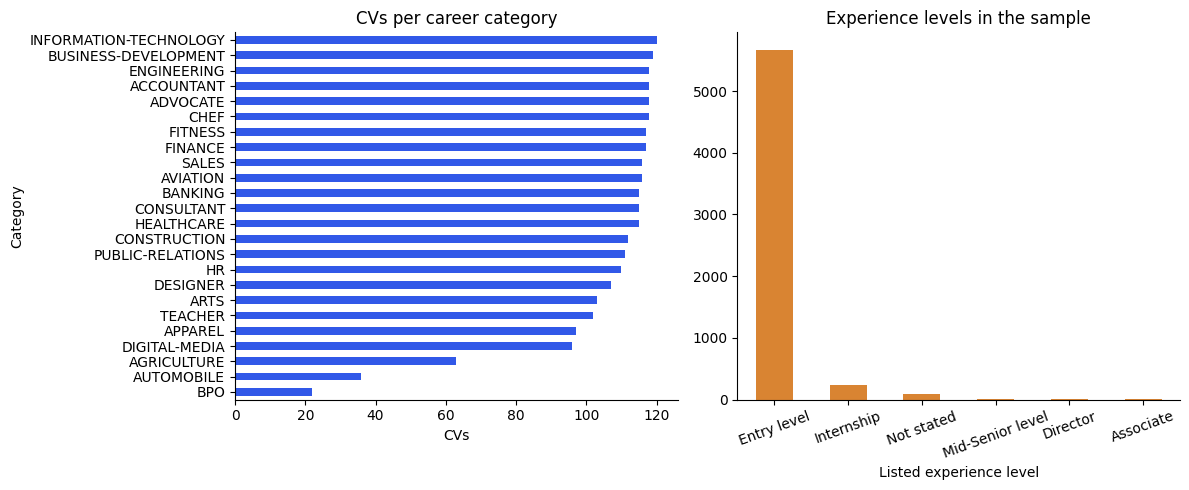

,Check,Value
0,Median cleaned CV length (words),733
1,Median job length (words),512
2,Expired sampled postings,6000
3,Sampled postings,6000


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
resumes.Category.value_counts().sort_values().plot.barh(ax=axes[0], color='#3158E8')
axes[0].set_title('CVs per career category'); axes[0].set_xlabel('CVs')
jobs.formatted_experience_level.replace('', 'Not stated').value_counts().plot.bar(ax=axes[1], color='#D98432')
axes[1].set_xlabel('Listed experience level'); axes[1].set_title('Experience levels in the sample'); axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()
display(pd.DataFrame({'Check': ['Median cleaned CV length (words)', 'Median job length (words)',
                              'Expired sampled postings', 'Sampled postings'],
                      'Value': [int(resumes.text.str.split().str.len().median()),
                                int(jobs.text.str.split().str.len().median()),
                                int(jobs.is_expired.sum()), len(jobs)]}))

**What this means:** the CV categories are uneven, so we preserve category proportions when splitting them. The sampled jobs are historical, not a current Kenyan vacancy feed. We use them to study matching; the app separately receives approved active vacancies from its backend. International job text does not establish that a Kenyan student is eligible.

Some internship-labelled records also carry senior experience labels. That is a data-quality warning, not proof that they suit a student. We preserve those labels for review and check current vacancies separately in the app.

## 4. Compare the approaches
We have separate tasks, not competing names for the same thing:

| Task | What we use | Simple explanation |
|---|---|---|
| Find jobs | TF-IDF baseline versus MiniLM | Compare matching words versus matching meaning. |
| Identify skill gaps | ESCO lookup and rules | Compare skills mentioned in a profile with the job's requirements. |
| Understand feedback tone | VADER versus logistic regression | Compare fixed sentiment rules with a classifier trained on labelled text. |
| Earlier supporting exercise | Career-category classifiers | Predict a broad CV field; this does not decide the job ranking. |

**NLP** means working with language. **Sentiment analysis** is the task of recognising tone. **Logistic regression** is a method we train for that task. **MiniLM** is an existing language model we reuse for job matching; we did not train or fine-tune MiniLM ourselves.

### 4.1 Supporting career-category comparison
We keep 20% of the cleaned CVs for testing. The remaining 80% is used to train and compare settings using three smaller training/validation splits. Vocabulary is learned only inside the training pipeline. The best validation result selects the classifier; the test set is not used to choose it.

**Accuracy** means the share of correct categories. **Macro F1** summarises wrong and missed labels, giving every category equal importance. This is a category exercise, not job-matching accuracy.

In [14]:
career_model, train_ids, test_ids, career_winner = career_comparison(resumes, RESULTS)
display(pd.read_csv(RESULTS / 'career_test_metrics.csv').round(3))
print('Selected using training validation:', career_winner)
assert set(train_ids).isdisjoint(test_ids)

Career comparison: Logistic regression


Career comparison: Linear SVM


Career comparison: Complement Naive Bayes


Career comparison: Majority baseline


Career winner selected by CV: Linear SVM


                 model  accuracy  macro_f1
   Logistic regression  0.645875  0.603993
            Linear SVM  0.665996  0.623170
Complement Naive Bayes  0.583501  0.517081
     Majority baseline  0.048290  0.003839


,model,accuracy,macro_f1
0,Logistic regression,0.646,0.604
1,Linear SVM,0.666,0.623
2,Complement Naive Bayes,0.584,0.517
3,Majority baseline,0.048,0.004


Selected using training validation: Linear SVM


### 4.2 Baseline: match important words
TF-IDF gives more weight to useful words than common words. We learn its vocabulary from training CVs and the available job catalogue, then compare each new profile with the jobs. This is our simple reference method.

In [15]:
retriever = TfidfVectorizer(token_pattern=TOKEN_PATTERN, ngram_range=(1, 2),
                            min_df=2, max_df=.95, max_features=40000, sublinear_tf=True)
retriever.fit(pd.concat([resumes.loc[train_ids, 'text'], jobs.text], ignore_index=True))
job_vectors = retriever.transform(jobs.text)
print('Word-based job index:', job_vectors.shape)
job_skills = []
for row in jobs.itertuples():
    found = lexicon.job_skills(row.title + '\n' + row.description + '\n' + str(row.skills_desc))
    job_skills.append({key: found[key] for key in ['required', 'preferred', 'mentioned', 'excluded']})
print('Skill requirements checked for', len(job_skills), 'postings.')

Word-based job index: (6000, 40000)


Skill requirements checked for 6000 postings.


### 4.3 Meaning-based matching: MiniLM
MiniLM represents each text as numbers that capture its meaning. We compare the profile and job representations; closer descriptions receive higher scores. This comparison is called **cosine similarity**. It is not a probability of getting hired.

We reuse a fixed pretrained version. Long texts use up to four sampled sections, so some details may be missed. The same settings and prediction functions are used by the app.

In [16]:
saved_encoder = os.environ.get('UPSHIFT_ENCODER_PATH')
encoder = load_encoder(saved_encoder) if saved_encoder else load_encoder()
semantic_vectors = encode_documents(encoder, jobs.text.tolist(), DATA / 'semantic_job_vectors.npy')
print('Meaning-based job index:', semantic_vectors.shape)
print('Pretrained encoder:', MODEL_ID)
print('Fine-tuned by our team: No')

C:\Users\HAFSA\OneDrive - Strathmore University\Documents\ChatGPT\uplift\.venv-ai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Embedding 6000 documents in 21545 sampled chunks


Batches:   0%|          | 0/674 [00:00<?, ?it/s]

Batches:   0%|          | 1/674 [00:02<28:28,  2.54s/it]

Batches:   0%|          | 2/674 [00:04<25:53,  2.31s/it]

Batches:   0%|          | 3/674 [00:06<24:15,  2.17s/it]

... (668 outputs left out)

Batches: 100%|█████████▉| 672/674 [19:15<00:00,  6.16it/s]

Batches: 100%|██████████| 674/674 [19:15<00:00,  8.17it/s]

Batches: 100%|██████████| 674/674 [19:15<00:00,  1.71s/it]

Meaning-based job index: (6000, 384)
Pretrained encoder: sentence-transformers/all-MiniLM-L6-v2
Fine-tuned by our team: No


### 4.4 Train feedback classification and compare it with VADER
Our three original CSVs have no feedback-tone labels. We therefore use the separately labelled **TweetEval** English sentiment dataset. Its training, validation and test sets stay separate; blank, repeated and conflicting texts are removed. Training learns word patterns, validation chooses settings, and testing measures the final result.

We compare trained logistic regression with VADER's fixed rules and a majority-label baseline. This evaluates English tweets, not Kenyan student feedback. Feedback tone never changes a student's job ranking.

In [17]:
TWEET_SOURCE = {'dataset': 'TweetEval sentiment / SemEval-2017 Task 4', 'repository': 'https://github.com/cardiffnlp/tweeteval', 'revision': '4fbd22cd78421f05b1ecdb4fc5725bc7a7bd8f66', 'use': 'external English sentiment benchmark, not evidence of performance on Kenyan app feedback'}
tweet_folder = DATA / 'sentiment'
tweet_folder.mkdir(exist_ok=True)
(tweet_folder / 'source.json').write_text(json.dumps(TWEET_SOURCE), encoding='utf-8')
sentiment, sentiment_metrics = sentiment_benchmark(DATA, RESULTS)
display(sentiment_metrics[['method', 'accuracy', 'macro_f1']].round(3))
print('Selected on validation data:', sentiment['selected'])
display(pd.read_json(RESULTS / 'sentiment_data_audit.json').T[['original', 'used']])

Training sentiment: Logistic regression C=0.5, weight=None


Training sentiment: Logistic regression C=0.5, weight=balanced


Training sentiment: Logistic regression C=2.0, weight=None


Training sentiment: Logistic regression C=2.0, weight=balanced


                      method  accuracy  macro_f1  prediction_seconds
           Majority baseline  0.483343  0.217231            0.004782
               VADER default  0.529690  0.526246            4.054165
      VADER validation-tuned  0.554940  0.538190            3.888073
TF-IDF + logistic regression  0.593549  0.590534            0.795179


,method,accuracy,macro_f1
0,Majority baseline,0.483,0.217
1,VADER default,0.530,0.526
2,VADER validation-tuned,0.555,0.538
3,TF-IDF + logistic regression,0.594,0.591


Selected on validation data: logistic


,original,used
train,45615,45582
val,2000,2000
test,12284,12277


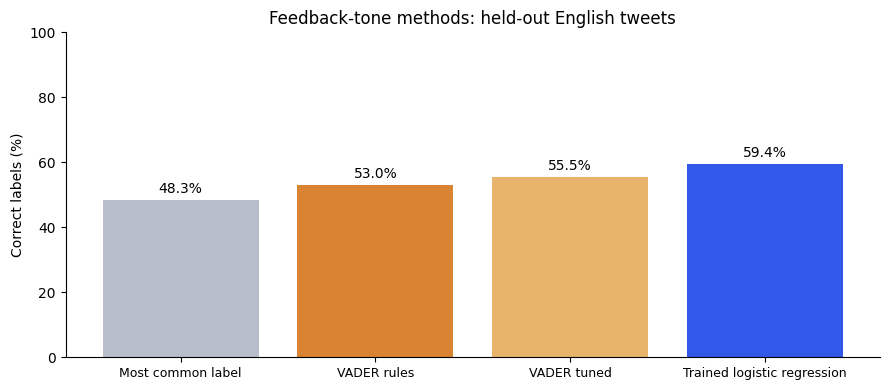

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
names = ['Most common label', 'VADER rules', 'VADER tuned', 'Trained logistic regression']
values = sentiment_metrics.accuracy.to_numpy() * 100
bars = ax.bar(names, values, color=['#B7BDC9', '#D98432', '#E8B36B', '#3158E8'])
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in values], padding=3)
ax.set_ylim(0, 100); ax.set_ylabel('Correct labels (%)')
ax.set_title('Feedback-tone methods: held-out English tweets')
ax.tick_params(axis='x', labelsize=9)
plt.tight_layout(); plt.show()

The chart compares the same held-out tweet test set. These are not measurements of job-matching accuracy or Kenyan student feedback.

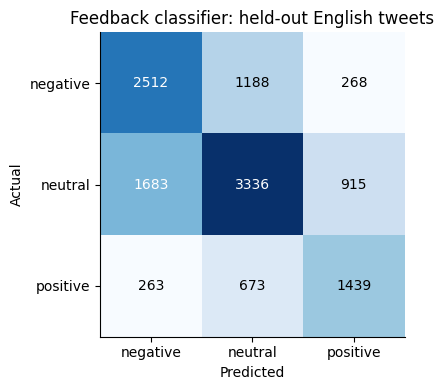

In [3]:
reports = json.loads((RESULTS / 'sentiment_reports.json').read_text())
matrix = np.array(reports['TF-IDF + logistic regression']['confusion_matrix'])
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(matrix, cmap='Blues')
labels = ['negative', 'neutral', 'positive']
ax.set_xticks(range(3), labels); ax.set_yticks(range(3), labels)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Feedback classifier: held-out English tweets')
for i in range(3):
    for j in range(3): ax.text(j, i, str(matrix[i,j]), ha='center', va='center', color='white' if matrix[i,j] > matrix.max()/2 else 'black')
plt.tight_layout(); plt.show()

## 5. Evaluate the job ranking
We compare the two matchers on 12 fictional student profiles: six for choosing the approach and six held aside for the final comparison. A small review rated the combined top-five suggestions from both methods:

- **0:** not relevant; **1:** partly relevant; **2:** a good match.
- **Precision@5:** how many of the five suggestions were rated good matches.
- **NDCG@5:** whether better-rated jobs appear nearer the top; higher is better. Here it only covers the jobs reviewed from both lists.

The ratings were **AI-assisted**, not independent human reviews. These results are a preliminary comparison, not proof of accuracy for all Kenyan students. Eligibility and whether a job is still open are separate from relevance. We choose the method using validation ranking quality, with Precision@5 as a tie-breaker; the test results do not choose the model.

In [19]:
from io import StringIO
profiles = pd.read_csv(StringIO('profile_id,split,field,profile_text\r\nSP01,validation,computing,"Year 3 undergraduate computing student in Kenya seeking a first software internship. Python, JavaScript, HTML, CSS, Git and SQL. Built a Flask REST API and a small React interface; wrote basic pytest tests. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP02,test,computing,"Year 3 undergraduate computing student in Kenya seeking a first software internship. Kotlin, Android Studio, Firebase and Git. Built a student expense tracker with authentication and a database; basic unit testing. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP03,validation,finance,"Year 3 undergraduate finance student in Kenya seeking a first finance or accounting internship. Excel, bookkeeping, bank reconciliation and financial statements. Coursework project preparing a budget and cash-flow spreadsheet; no professional certification. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP04,test,finance,"Year 3 undergraduate finance student in Kenya seeking a first finance or accounting internship. Accounting and finance student with Excel, QuickBooks practice and accounts payable coursework. Prepared ledger entries and reconciliations in a class project. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP05,validation,marketing,"Year 3 undergraduate marketing student in Kenya seeking a first marketing internship. Canva, social media content, copywriting and Excel. Planned a student-club Instagram campaign and tracked reach and engagement. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP06,test,marketing,"Year 3 undergraduate marketing student in Kenya seeking a first marketing internship. Google Analytics introductory practice, market research, survey design and PowerPoint. Analysed a student business customer survey; basic digital advertising knowledge. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP07,validation,human_resources,"Year 3 undergraduate human resources student in Kenya seeking a first human resources internship. HR management student with recruitment administration coursework, Excel, record keeping and clear writing. Organised volunteer interviews for a campus club. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP08,test,human_resources,"Year 3 undergraduate human resources student in Kenya seeking a first human resources internship. Human resources student with onboarding, employee records, communication and basic labour-relations coursework. Used Excel to organise attendance for a student society. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP09,validation,engineering,"Year 3 undergraduate engineering student in Kenya seeking a first engineering internship. Mechanical engineering student with AutoCAD, SolidWorks, technical drawings and workshop safety coursework. Designed a simple pump assembly as a university project. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP10,test,engineering,"Year 3 undergraduate engineering student in Kenya seeking a first engineering internship. Electrical engineering student with circuit analysis, MATLAB, basic PLC programming and electrical safety. Built and documented a small sensor-monitoring project. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP11,validation,digital_media,"Year 3 undergraduate digital media student in Kenya seeking a first digital media or design internship. Figma, Adobe Illustrator and Photoshop. Designed a campus-event poster and a mobile interface prototype; has a small student portfolio. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\nSP12,test,digital_media,"Year 3 undergraduate digital media student in Kenya seeking a first digital media or design internship. Adobe Premiere Pro, photography, video editing and storytelling. Produced a short student documentary and social-media clips; basic audio editing. No full-time professional experience. Open to international roles only where location and work-authorisation requirements permit; availability and eligibility must be checked separately."\r\n'))
ratings = pd.read_csv(StringIO('profile_id,job_id,relevance\r\nSP02,3902308577,1\r\nSP11,3898166973,1\r\nSP06,3898166973,2\r\nSP11,3906223961,0\r\nSP01,3902837870,1\r\nSP07,3905303182,2\r\nSP04,3891262956,1\r\nSP05,3905282267,2\r\nSP07,3906076205,1\r\nSP04,3904368419,0\r\nSP02,3895207460,1\r\nSP07,3905801031,0\r\nSP12,3889126926,2\r\nSP08,3905327959,0\r\nSP05,3905249747,2\r\nSP12,3902785697,2\r\nSP07,3906227054,0\r\nSP08,3905303182,2\r\nSP10,3891073997,2\r\nSP08,3905801031,0\r\nSP06,3888051149,2\r\nSP02,3904501087,1\r\nSP04,3904432250,2\r\nSP02,3902837870,1\r\nSP09,3900942594,0\r\nSP03,3891071407,0\r\nSP12,3901679325,1\r\nSP11,3903839921,1\r\nSP01,3887701048,1\r\nSP05,3904929053,2\r\nSP01,3901352285,0\r\nSP05,3894926271,2\r\nSP04,3887906634,0\r\nSP06,3892295396,1\r\nSP12,3902757165,2\r\nSP04,3891071407,0\r\nSP11,3898166879,1\r\nSP10,3904368369,2\r\nSP02,3902842422,0\r\nSP06,3903456269,0\r\nSP11,3901679325,2\r\nSP01,3891007362,0\r\nSP11,3903458189,1\r\nSP01,3902868196,2\r\nSP10,3905396269,1\r\nSP01,3905693233,0\r\nSP11,3895828898,1\r\nSP10,3901396124,0\r\nSP06,3905377271,0\r\nSP09,3902837870,0\r\nSP04,3899525228,1\r\nSP08,3901948185,0\r\nSP05,3895828898,2\r\nSP06,3902328120,2\r\nSP12,3891253220,2\r\nSP08,3898164242,1\r\nSP07,3901936391,0\r\nSP12,3895828898,2\r\nSP08,3901936391,0\r\nSP07,3902344478,1\r\nSP12,3905282267,2\r\nSP03,3889776778,1\r\nSP01,3900081441,0\r\nSP11,3884932105,1\r\nSP09,3904719736,2\r\nSP10,3904503803,1\r\nSP07,3902820941,1\r\nSP08,3906076205,1\r\nSP10,3906250452,0\r\nSP06,3905256254,2\r\nSP09,3891007362,0\r\nSP11,3900078697,0\r\nSP09,3904503803,0\r\nSP09,3902943197,0\r\nSP04,3886897525,0\r\nSP02,3886897217,0\r\nSP03,3891259796,0\r\nSP09,3891041847,0\r\nSP03,3904432250,2\r\nSP03,3891262956,1\r\nSP01,3900943289,1\r\nSP06,3902842984,0\r\nSP09,3906223198,0\r\nSP08,3902344478,1\r\nSP12,3811513595,2\r\nSP05,3891036360,2\r\nSP03,3906258414,0\r\nSP10,3885866834,0\r\nSP04,3894604764,1\r\nSP02,3904566832,0\r\nSP03,3904409589,0\r\nSP05,3895501969,2\r\nSP07,3901948185,0\r\nSP06,3905372904,0\r\nSP04,3906229717,0\r\nSP02,3887701048,1\r\nSP12,3894926271,1\r\nSP06,3895207460,1\r\nSP09,3905690447,1\r\nSP03,3884935447,1\r\nSP05,3890899712,2\r\nSP03,3904958338,1\r\nSP03,3903843102,2\r\nSP01,3903830264,0\r\nSP02,3889484364,0\r\nSP05,3483544074,2\r\nSP02,3904953432,1\r\nSP09,3900939794,0\r\nSP11,3891253220,2\r\nSP10,3904719736,2\r\nSP08,3906227054,0\r\nSP05,3903458189,2\r\n'), dtype={'job_id': str})
assert profiles.profile_id.nunique() == 12
assert not ratings.duplicated(['profile_id', 'job_id']).any()
display(profiles.groupby('split').size().rename('Fictional profiles').to_frame())
print('Frozen reviewed profile/job pairs:', len(ratings))

,Fictional profiles
split,
test,6
validation,6


Frozen reviewed profile/job pairs: 112


In [20]:
bundle = {'schema_version': 2, 'retriever': retriever, 'job_vectors': job_vectors,
          'semantic_vectors': semantic_vectors, 'jobs': jobs, 'job_skills': job_skills,
          'lexicon': lexicon, 'career_model': career_model, 'sentiment': sentiment}
ranking_rows = []
for profile in profiles.itertuples():
    for method in ['lexical', 'semantic']:
        matches = recommend(bundle, profile.profile_text, top_k=5, method=method, encoder=encoder)['matches']
        for rank, job in enumerate(matches, 1):
            ranking_rows.append({'profile_id': profile.profile_id, 'split': profile.split,
                                 'method': method, 'rank': rank, 'job_id': str(job['job_id'])})
rankings = pd.DataFrame(ranking_rows)
scored = rankings.merge(ratings, on=['profile_id', 'job_id'], how='left', validate='many_to_one')
assert scored.relevance.notna().all(), 'New candidates need ratings; do not invent missing labels.'
def dcg(grades): return sum((2**grade - 1) / math.log2(i+2) for i, grade in enumerate(grades))
rows = []
for (pid, split, method), group in scored.groupby(['profile_id','split','method']):
    grades = group.sort_values('rank').relevance.tolist()
    pool = scored[scored.profile_id.eq(pid)].drop_duplicates('job_id').relevance.tolist()
    ideal = dcg(sorted(pool, reverse=True)[:5])
    rows.append({'profile_id':pid, 'split':split, 'method':method,
                 'precision_at_5':sum(g == 2 for g in grades)/5,
                 'pooled_ndcg_at_5':dcg(grades)/ideal if ideal else 0,
                 'has_good_match':int(2 in grades)})
review_metrics = pd.DataFrame(rows)
summary = review_metrics.groupby(['split','method']).agg(
    precision_at_5=('precision_at_5','mean'), pooled_ndcg_at_5=('pooled_ndcg_at_5','mean'),
    good_match_coverage=('has_good_match','mean'), profiles=('profile_id','count')).reset_index()
validation = summary[summary.split.eq('validation')].sort_values(
    ['pooled_ndcg_at_5','precision_at_5','method'], ascending=[False,False,True])
selected_method = validation.iloc[0]['method']
display(summary.round(3))
print('Selected using validation:', selected_method)
summary.to_csv(RESULTS / 'matching_comparison.csv', index=False)
review_metrics.to_csv(RESULTS / 'matching_per_profile.csv', index=False)
rankings.to_csv(RESULTS / 'ranking_ids.csv', index=False)

Embedding 1 documents in 1 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 17.29it/s]

Embedding 1 documents in 1 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 20.57it/s]

... (29 outputs left out)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 13.85it/s]

,split,method,precision_at_5,pooled_ndcg_at_5,good_match_coverage,profiles
0,test,lexical,0.267,0.480,0.500,6
1,test,semantic,0.333,0.774,0.833,6
2,validation,lexical,0.200,0.400,0.333,6
3,validation,semantic,0.367,0.642,1.000,6


Selected using validation: semantic


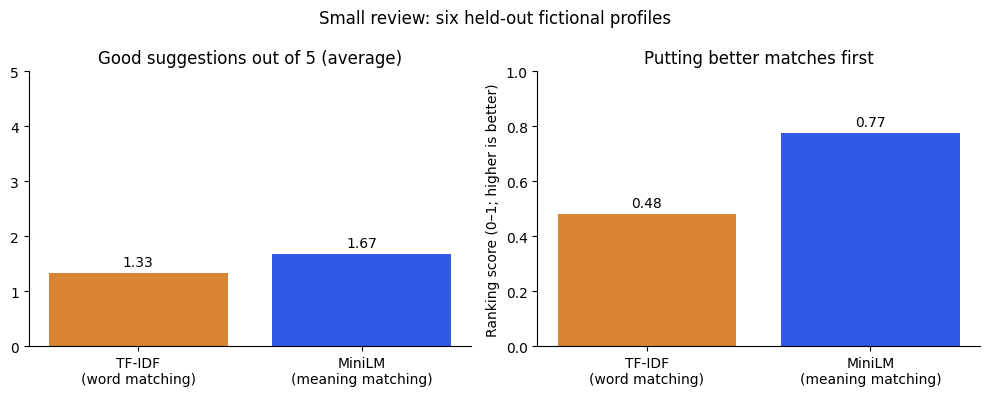

In [3]:
test_scores = summary[summary.split.eq('test')].set_index('method').loc[['lexical','semantic']]
names = ['TF-IDF\n(word matching)', 'MiniLM\n(meaning matching)']
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, values, title, top in [
    (axes[0], test_scores.precision_at_5 * 5, 'Good suggestions out of 5 (average)', 5),
    (axes[1], test_scores.pooled_ndcg_at_5, 'Putting better matches first', 1)]:
    bars = ax.bar(names, values, color=['#D98432','#3158E8'])
    ax.bar_label(bars, fmt='%.2f', padding=3)
    ax.set_ylim(0, top); ax.set_title(title)
axes[1].set_ylabel('Ranking score (0–1; higher is better)')
fig.suptitle('Small review: six held-out fictional profiles', fontsize=12)
plt.tight_layout(); plt.show()

The ranking score gives some credit to partly relevant jobs; the good-suggestion count only includes jobs rated 2. These six test profiles use the disclosed AI-assisted ratings.

**How to explain the results:** Precision@5 describes good matches in the first five suggestions. NDCG describes their order. Neither is a percentage chance of employment, and NDCG must not be called “matching accuracy.” This small review needs independent human checking and more representative Kenyan vacancies before making stronger claims.

## 6. Save the final model in the app's format
We save one **schema-2 bundle**, meaning the file structure expected by our backend: the trained word models, job index and skill lookup. We also save the pretrained encoder and the selected matching method. The app's backend loads these files through `ModelService`. There is no second teaching export or separate toy API in this notebook. Training happens here once; the phone uses the saved engine instead of retraining.

The app backend handles sign-in, approved vacancies, expiry and location/experience rules. The model ranks the vacancies it receives. The guided coach and feedback submission are app features, not additional trained models.

In [21]:
joblib.dump(bundle, ARTIFACTS / 'upshift_bundle.joblib', compress=3)
encoder.save(str(ARTIFACTS / 'semantic_encoder'))
deployment = {'schema_version': 2, 'selected_method': selected_method,
              'review_status': 'completed_single_ai_assisted_review',
              'independent_human_review': False, 'sentiment_optional': True,
              'catalogue_status': 'historical_research_not_live'}
(ARTIFACTS / 'deployment_config.json').write_text(json.dumps(deployment, indent=2))
shutil.copytree('upshift_ai', ARTIFACTS / 'upshift_ai', dirs_exist_ok=True,
                ignore=shutil.ignore_patterns('__pycache__'))
service = ModelService(ARTIFACTS)
service.prepare()
print('Reloaded successfully:', service.method, '| bundle schema:', service.bundle['schema_version'])

Reloaded successfully: semantic | bundle schema: 2


## 7. Try the same prediction function used by the app
These two vacancies and student profiles are **fictional demonstration data**, not real advertisements. We supply the same profile text and vacancy fields the backend passes to the model. First compare a Python/SQL profile with an Android/Kotlin profile. Then add an honestly stated skill and check the explanation changes.

Changing evidence can change the order and skill gaps. Adding a word does not guarantee a higher meaning score. Live job eligibility is checked separately by the backend.

In [22]:
demo_jobs = [
    {'job_id':'demo-python', 'title':'Python Software Intern', 'company_name':'Demo Employer',
     'description':'Build Python APIs, write SQL queries and test backend applications.',
     'requirements':['Python, SQL, Git and Docker are required.']},
    {'job_id':'demo-android', 'title':'Android Developer Intern', 'company_name':'Demo Employer',
     'description':'Build Android mobile applications using Kotlin and Firebase.',
     'requirements':['Kotlin, Android, Firebase and Git are required.']}]
demo_profiles = {
    'Python student':'Year 3 computing student seeking a backend internship. Python and SQL. Built and tested a Flask API with SQL queries.',
    'Android student':'Year 3 computing student seeking a mobile internship. Kotlin, Android, Firebase and Git. Built an Android expense tracker with authentication.'}
demo_results = {}
for name, text in demo_profiles.items():
    result = service.rank_vacancies(text, demo_jobs, top_k=2)
    demo_results[name] = result
    print(name)
    display(pd.DataFrame([{'Job': m['title'], 'Similarity': m['similarity'],
                           'Skills that match': ', '.join(s['label'] for s in m['matched_skills']),
                           'Skills to check': ', '.join(s['label'] for s in m['required_skills_not_mentioned'])}
                          for m in result['matches']]))
assert demo_results['Python student']['matches'][0]['job_id'] == 'demo-python'
assert demo_results['Android student']['matches'][0]['job_id'] == 'demo-android'
updated = service.rank_vacancies(demo_profiles['Python student'] + ' Used Git and Docker in this project.', demo_jobs, 2)
python_job = next(m for m in updated['matches'] if m['job_id']=='demo-python')
assert not python_job['required_skills_not_mentioned']
print('After adding demonstrated Git and Docker skills: no listed Python-role skill gaps remain.')

Embedding 3 documents in 3 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  9.38it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  9.13it/s]

Python student


,Job,Similarity,Skills that match,Skills to check
0,Python Software Intern,0.743211,"SQL, Python","Docker, Git"
1,Android Developer Intern,0.262382,,"Android, Firebase, Git, Kotlin"


... (6 outputs left out)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  6.36it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  6.11it/s]

After adding demonstrated Git and Docker skills: no listed Python-role skill gaps remain.


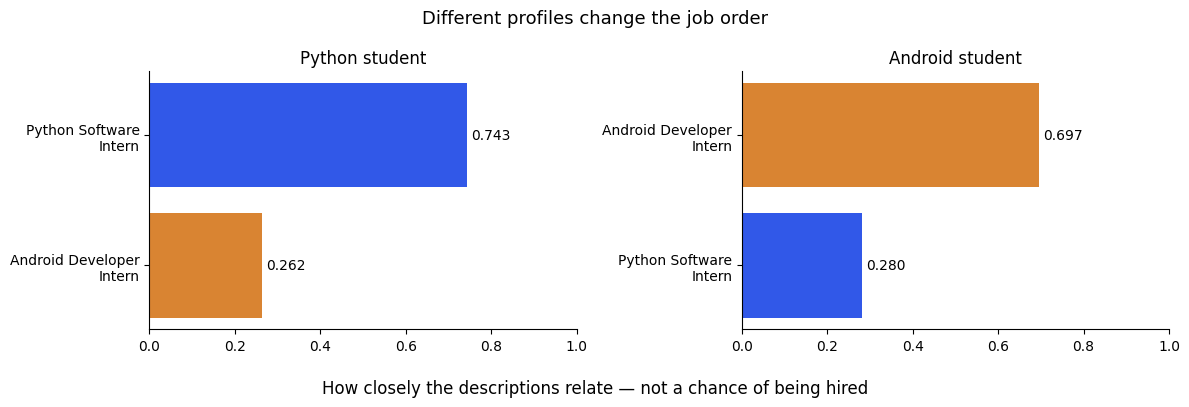

In [4]:
from textwrap import fill
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, result) in zip(axes, demo_results.items()):
    matches = result['matches']
    bars = ax.barh([fill(m['title'], 19) for m in matches],
                   [m['similarity'] for m in matches],
                   color=['#3158E8' if m['job_id']=='demo-python' else '#D98432' for m in matches])
    ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_title(name)
    ax.bar_label(bars, fmt='%.3f', padding=3)
fig.suptitle('Different profiles change the job order', fontsize=13)
fig.supxlabel('How closely the descriptions relate — not a chance of being hired')
plt.tight_layout(); plt.show()

The same two fictional jobs are ranked for different profiles. The order changes with the evidence supplied; the numbers are not hiring probabilities.

### A short explanation for the student
The app's **Why this job?** section says: “We compared your profile with what this job asks for.” It shows matching skills and skills the profile does not mention. If the student has a missing skill, they can add evidence to their profile. A match does not guarantee a job.

This skill comparison supports understanding; it is a separate rule-based check, not a breakdown of every part of MiniLM's score. The percentage circles in Browse show listed-skills coverage; For you uses the meaning-based ranking.

### 7.1 Invalid inputs and empty results
The model must reject blank profiles and invalid result limits. An empty approved vacancy list should return no matches, rather than old research jobs. The app also validates experience months and shows a helpful popup for failed requests.

In [23]:
checks = []
for name, text, limit in [('Blank profile', '   ', 2), ('Invalid limit', demo_profiles['Python student'], 0),
                          ('Boolean limit', demo_profiles['Python student'], True)]:
    try:
        service.rank_vacancies(text, demo_jobs, limit)
    except ValueError as error:
        checks.append({'Input':name, 'Outcome':'Rejected', 'Reason':str(error)})
    else:
        raise AssertionError(f'{name} should be rejected')
empty = service.rank_vacancies(demo_profiles['Python student'], [], 2)
assert empty['status']=='no_match' and empty['matches']==[]
checks.append({'Input':'No approved vacancies', 'Outcome':'No matches', 'Reason':'No historical fallback'})
display(pd.DataFrame(checks))

,Input,Outcome,Reason
0,Blank profile,Rejected,"Provide 1 to 50,000 characters of CV text."
1,Invalid limit,Rejected,top_k must be 1 to 20.
2,Boolean limit,Rejected,top_k must be 1 to 20.
3,No approved vacancies,No matches,No historical fallback


### 7.2 Feedback tone: examples and a known mistake
We test different messages through the saved sentiment model. We also show a difficult example: mixed praise and criticism can confuse it. Sending feedback is a separate save operation; saving a message does not mean its tone was classified correctly.

In [24]:
feedback_cases = [
    ('I love the clear explanations and useful learning resources.', 'positive'),
    ('All these vacancies expired last year. This is frustrating.', 'negative'),
    ('The screen displays five recommendations.', 'neutral'),
    ('The layout is nice, but all the jobs are expired and unusable.', 'negative')]
feedback_results = pd.DataFrame([{'Feedback':text, 'Expected':expected,
                                  'Predicted':service.sentiment(text)['label']}
                                 for text,expected in feedback_cases])
display(feedback_results)
print('These authored examples illustrate behaviour; they are not an independent evaluation dataset.')

,Feedback,Expected,Predicted
0,I love the clear explanations and useful learning resources.,positive,positive
1,All these vacancies expired last year. This is frustrating.,negative,negative
2,The screen displays five recommendations.,neutral,neutral
3,"The layout is nice, but all the jobs are expired and unusable.",negative,positive


These authored examples illustrate behaviour; they are not an independent evaluation dataset.


## 8. Check the handoff
Reloading must preserve the predictions. The exported files can be given to the backend teammate; they do not contain passwords or Firebase keys. Joblib files should only be loaded from trusted project sources. The ZIP is generated locally because model files are too large for a normal GitHub commit.

In [25]:
reloaded = ModelService(ARTIFACTS)
reloaded.prepare()
for text in demo_profiles.values():
    assert reloaded.rank_vacancies(text, demo_jobs, 2) == service.rank_vacancies(text, demo_jobs, 2)
assert reloaded.sentiment(feedback_cases[0][0]) == service.sentiment(feedback_cases[0][0])
packages = ['numpy','pandas','scipy','scikit-learn','joblib','nltk','torch','sentence-transformers','transformers']
metadata = {'seed':SEED, 'python':platform.python_version(),
            'versions':{name:importlib.metadata.version(name) for name in packages},
            'raw_data_sha256':{p.name:fingerprint(p) for p in [resume_path,jobs_path,skills_path]},
            'encoder':MODEL_ID, 'encoder_revision':MODEL_REVISION, 'fine_tuned':False,
            'selected_method':selected_method, 'independent_human_review':False,
            'rating_source':'single AI-assisted review',
            'test_metrics':summary[(summary.split=='test') & (summary.method==selected_method)].to_dict('records')}
(ARTIFACTS / 'metadata.json').write_text(json.dumps(metadata, indent=2))
(RESULTS / 'demo_inputs.json').write_text(json.dumps({'profiles':demo_profiles,'jobs':demo_jobs},indent=2))
(RESULTS / 'demo_outputs.json').write_text(json.dumps(demo_results,indent=2))
shutil.make_archive('UpShift_Final_Model', 'zip', ARTIFACTS)
print('PASS: saved and reloaded predictions agree.')
print('Backend files: artifacts/upshift_bundle.joblib, artifacts/deployment_config.json, artifacts/semantic_encoder/')
print('Model handoff archive: UpShift_Final_Model.zip')

Embedding 3 documents in 3 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 12.17it/s]

Embedding 3 documents in 3 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 16.62it/s]

... (3 outputs left out)

Embedding 3 documents in 3 sampled chunks


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 20.12it/s]

PASS: saved and reloaded predictions agree.
Backend files: artifacts/upshift_bundle.joblib, artifacts/deployment_config.json, artifacts/semantic_encoder/
Model handoff archive: UpShift_Final_Model.zip


## 9. Conclusion and limits
We compared word-based and meaning-based job matching and chose the approach using the validation profiles. We trained and tested a separate feedback classifier, added skill explanations, checked different and invalid inputs, and saved the app-compatible model files.

The main limits are a historical international job sample, a small AI-assisted relevance review, and feedback training on English tweets. Independent human review, representative Kenyan vacancies and student-feedback testing are still needed. This notebook does not prove that using the app improves employment outcomes.

**For the live demo:** enter a profile → find jobs → open Why this job? → change the profile → compare results → show one invalid input. Explain that the app checks rules such as experience separately from the model ranking.

## Sources and earlier work
- Original project data: Resume.csv and postings.csv (Kaggle), skills_en.csv ([ESCO](https://esco.ec.europa.eu/en/use-esco/download)). Retain the exact original download records, licences and attribution with the group's datasets; this notebook does not redistribute their raw contents.
- [Team dataset folder](https://drive.google.com/drive/folders/1OS_u2gUFYCGqZtl-Q2izLvgZZSFi9ZS9).
- [MiniLM model](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), fixed revision printed in the saved metadata; pretrained, not fine-tuned here.
- [TweetEval sentiment benchmark](https://github.com/cardiffnlp/tweeteval), revision `4fbd22cd78421f05b1ecdb4fc5725bc7a7bd8f66`.
- [VADER](https://www.nltk.org/api/nltk.sentiment.vader.html), [scikit-learn](https://scikit-learn.org/stable/).
- `LogisticRegression_Base.ipynb` preserves our earlier base notebook. `01_cleaning.ipynb` and `Resume_Exploration.ipynb` remain in the repository as earlier work. This file is the final compiled model workflow.

**One-sentence explanation:** “We compare a student's profile with job descriptions, show skills to check, and rank suggestions; a separate trained classifier recognises the tone of feedback.”